In [4]:
import pandas as pd, xarray as xr, numpy as np, matplotlib as mpl
import matplotlib.pyplot as plt, seaborn as sns 
import pickle

from functions import EU_MEMBERS, fold_territories

In [5]:
## File path shortcuts
basepath = '/home/msaenger/Perceptions_2025/cleaned_code/'
spath = basepath + 'SI_Figures/'
cpath = basepath + 'CIDER_output/'

n_members = 500

newpath = basepath + f'{n_members}_members/'

In [6]:
ssp_plus_invert = xr.open_dataset(newpath + 
                    f'SSP370_plus_InVERT_{n_members}member_ensemble_TREFHT_2015_to_2065.nc')

In [7]:
# with open(newpath + 'f_by_country_no_SAI.pickle', 'rb') as handle:
#     f_by_country = pickle.load(handle)

with open(newpath + 'f_by_country_no_SAI_k=50_to_1500.pickle', 'rb') as handle:
    f_by_country = pickle.load(handle)

# ## Load saved dict of dates for first f threshold crossings by country (multiple k)
# with open(newpath + 'f_thresh_crossing_dates.pickle', 'rb') as handle:
#     f_crossing_dates = pickle.load(handle)

## Load saved dict of dates for first f threshold crossings by country (multiple k)
with open(newpath + 'f_thresh_crossing_dates_v3.pickle', 'rb') as handle:
    f_crossing_dates = pickle.load(handle)

In [8]:
print(list(f_by_country.keys()))

[50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625, 650, 675, 700, 725, 750, 775, 800, 825, 850, 875, 900, 925, 950, 975, 1000, 1050, 1100, 1150, 1200, 1250, 1300, 1350, 1400, 1450, 1500]


In [9]:
## Find time indices within target year 

target_median_f_crossing_year = 2050 # or 2035

time_indices = []

for t_idx in range(len(f_by_country[50].time.values)):
    
    if f_by_country[50].time.values[t_idx].year == target_median_f_crossing_year:
        
        time_indices.append(t_idx)

median_idx = np.median(time_indices)
median_idx

425.5

In [10]:
T_total = len(f_by_country[50].time)   # 600 months

## Dictionary to store the ensemble-median time index for each country's first f-crossing
f_crossing_median_t_indices = {} 

## Interate thru allcountries and k values
for country in f_crossing_dates[50].country.values:
    f_crossing_median_t_indices[country] = {}

    for k in list(f_by_country.keys()):
        
        ## Find all first-f-crossing time indices
        idx = f_crossing_dates[k].sel(
                    country=country).first_time_idx.values.astype(float)
        
        ## Set -1 indices (e.g. didn't cross) to 600 (e.g. "at least at end of time series")
        idx_censored = np.where(idx < 0, T_total, idx)  
        
        ## After adjusting for 'never-crossed' time index values, find median t index of first crossing
        f_crossing_median_t_indices[country][k] = np.median(idx_censored)

In [11]:
f_crossing_median_t_indices

{'United Kingdom': {50: 38.0,
  75: 71.0,
  100: 92.0,
  125: 117.0,
  150: 136.5,
  175: 173.0,
  200: 196.5,
  225: 215.5,
  250: 233.0,
  275: 239.5,
  300: 253.5,
  325: 270.5,
  350: 289.0,
  375: 292.0,
  400: 297.0,
  425: 307.0,
  450: 311.0,
  475: 320.5,
  500: 327.0,
  525: 333.0,
  550: 340.0,
  575: 344.0,
  600: 352.5,
  625: 357.0,
  650: 360.0,
  675: 364.0,
  700: 367.5,
  725: 377.0,
  750: 381.0,
  775: 390.5,
  800: 392.5,
  825: 396.5,
  850: 397.0,
  875: 402.0,
  900: 406.5,
  925: 408.5,
  950: 413.5,
  975: 416.0,
  1000: 417.5,
  1050: 426.0,
  1100: 433.5,
  1150: 445.5,
  1200: 455.5,
  1250: 461.5,
  1300: 462.0,
  1350: 463.0,
  1400: 469.0,
  1450: 487.0,
  1500: 487.0},
 'New Zealand': {50: 55.5,
  75: 81.0,
  100: 105.0,
  125: 119.5,
  150: 131.0,
  175: 145.5,
  200: 155.0,
  225: 164.0,
  250: 175.5,
  275: 187.0,
  300: 194.5,
  325: 201.5,
  350: 210.0,
  375: 214.0,
  400: 217.0,
  425: 223.5,
  450: 226.5,
  475: 232.0,
  500: 232.5,
  525: 236.0

### Find the k value which results in the ensemble median f_first_crossing date across the ensemble being closest to the chosen target year (2035 or 2050)

In [12]:
target = median_idx
data = f_crossing_median_t_indices

## Dict to store result (k value) for each country
results = {}

for country, ensemble_dict in data.items():
    closest_key = None
    closest_value = None
    min_diff = float('inf')

    for key, value in ensemble_dict.items():
        diff = abs(value - target)
        if diff < min_diff:
            min_diff = diff
            closest_key = key
            closest_value = value
    results[country] = closest_key

results

{'United Kingdom': 1050,
 'New Zealand': 1500,
 'Chile': 1500,
 'Australia': 1500,
 'Argentina': 1500,
 'South Africa': 1500,
 'France': 1350,
 'Uruguay': 1500,
 'Brazil': 1500,
 'Namibia': 1500,
 'Madagascar': 1500,
 'Tonga': 1450,
 'Mauritius': 1500,
 'Lesotho': 1500,
 'Mozambique': 1500,
 'Fiji': 1500,
 'Paraguay': 1500,
 'eSwatini': 1500,
 'Botswana': 1500,
 'Peru': 1500,
 'Bolivia': 1500,
 'Zimbabwe': 1500,
 'Vanuatu': 1500,
 'Ecuador': 1500,
 'Angola': 1450,
 'Zambia': 1500,
 'Samoa': 1500,
 'United States of America': 600,
 'Malawi': 1450,
 'Papua New Guinea': 1400,
 'Kiribati': 1500,
 'Comoros': 1500,
 'Indonesia': 1500,
 'Solomon Islands': 1450,
 'Democratic Republic of the Congo': 1400,
 'Seychelles': 1500,
 'United Republic of Tanzania': 1500,
 'East Timor': 1500,
 'Tuvalu': 1500,
 'São Tomé and Principe': 1500,
 'Gabon': 1500,
 'Ivory Coast': 1350,
 'Ghana': 1350,
 'Republic of the Congo': 1500,
 'Kenya': 1500,
 'Somalia': 1500,
 'Sri Lanka': 1500,
 'Nauru': 1300,
 'Mexico'

In [13]:
## Save dict of country-specific k for 2035 median first-f-threshold-crossing

with open(newpath + 'country_k_for_2050_median_f_crossing.pickle', 'wb') as handle:
    pickle.dump(results, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [14]:
with open(newpath + 'country_k_for_2050_median_f_crossing.pickle', 'rb') as handle:
    country_k = pickle.load(handle)
    
country_k

{'United Kingdom': 1050,
 'New Zealand': 1500,
 'Chile': 1500,
 'Australia': 1500,
 'Argentina': 1500,
 'South Africa': 1500,
 'France': 1350,
 'Uruguay': 1500,
 'Brazil': 1500,
 'Namibia': 1500,
 'Madagascar': 1500,
 'Tonga': 1450,
 'Mauritius': 1500,
 'Lesotho': 1500,
 'Mozambique': 1500,
 'Fiji': 1500,
 'Paraguay': 1500,
 'eSwatini': 1500,
 'Botswana': 1500,
 'Peru': 1500,
 'Bolivia': 1500,
 'Zimbabwe': 1500,
 'Vanuatu': 1500,
 'Ecuador': 1500,
 'Angola': 1450,
 'Zambia': 1500,
 'Samoa': 1500,
 'United States of America': 600,
 'Malawi': 1450,
 'Papua New Guinea': 1400,
 'Kiribati': 1500,
 'Comoros': 1500,
 'Indonesia': 1500,
 'Solomon Islands': 1450,
 'Democratic Republic of the Congo': 1400,
 'Seychelles': 1500,
 'United Republic of Tanzania': 1500,
 'East Timor': 1500,
 'Tuvalu': 1500,
 'São Tomé and Principe': 1500,
 'Gabon': 1500,
 'Ivory Coast': 1350,
 'Ghana': 1350,
 'Republic of the Congo': 1500,
 'Kenya': 1500,
 'Somalia': 1500,
 'Sri Lanka': 1500,
 'Nauru': 1300,
 'Mexico'

In [15]:
results == country_k

True

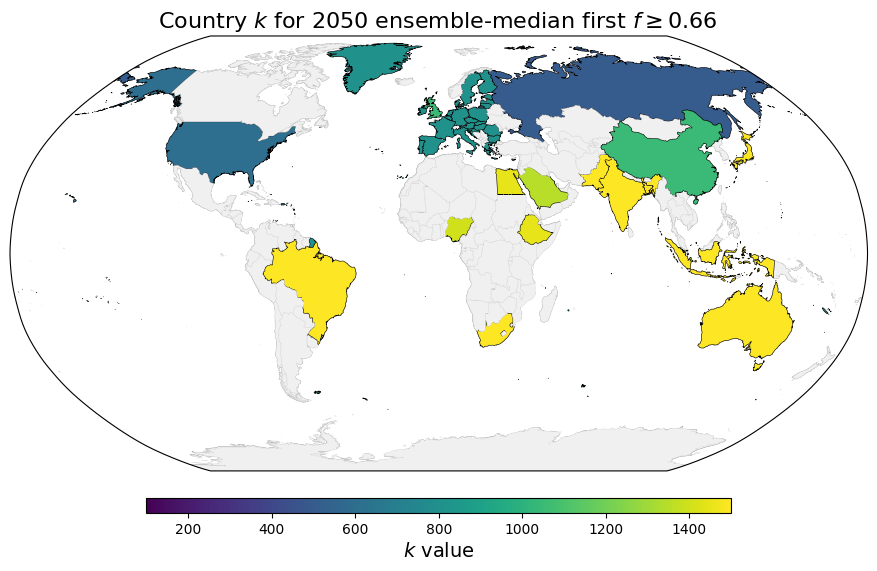

In [20]:
## Highlight specific countries, plus every EU member state shaded with the EU
## aggregate k value -- again using fold_territories' geometries so labels line up
## with country_k exactly, with no name_fixes hack required.

# Countries to plot with their own k value
target_countries = ['India', 'Australia', 'United States of America', 'Brazil', 'China',
            'Pakistan', 'Russia', 'Bangladesh', 'Nigeria', 'Japan', 'United Kingdom',
            'Egypt', 'Saudi Arabia', 'Ethiopia', 'South Africa', 'Indonesia']

# Current EU-27 member states, shaded with the 'European Union' k value.
# Reuses the same EU_MEMBERS list build_country_weights used upstream
eu_members = set(EU_MEMBERS)

countries_zip_path = basepath + 'natural_earth_data/ne_50m_admin_0_countries.zip'
countries_gdf, _ = fold_territories(countries_zip_path, keep_as_sovereign=['Palestine'], verbose=False)

eu_k = country_k['European Union']

cmap = plt.cm.viridis
# Normalize over just the k values actually being plotted (targets + EU)
plotted_vals = [country_k[c] for c in target_countries if c in country_k] + [eu_k]
norm = mpl.colors.Normalize(vmin=100, vmax=1500)##vmin=min(plotted_vals), vmax=max(plotted_vals))

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(linewidth=0.3, color='gray')

matched_keys = set()

for row in countries_gdf.itertuples():
    admin = row.ADMIN
    k_val = None
    matched_key = None

    if admin in eu_members:
        k_val = eu_k
        matched_key = 'European Union'
    elif admin in target_countries:
        k_val = country_k[admin]
        matched_key = admin
    if matched_key:
        matched_keys.add(matched_key)

    facecolor = cmap(norm(k_val)) if k_val is not None else '#f0f0f0'
    edgecolor = 'black' if k_val is not None else '#cccccc'
    linewidth = 0.4 if k_val is not None else 0.2

    ax.add_geometries([row.geometry], ccrs.PlateCarree(),
        facecolor=facecolor, edgecolor=edgecolor, linewidth=linewidth)

expected = set(target_countries) | {'European Union'}
unmatched = expected - matched_keys
if unmatched:
    print("Unmatched (check target_countries spelling against ADMIN names):", unmatched)

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm._A = []
cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.05, shrink=0.5, aspect=40)
cbar.set_label(f'$k$ value', fontsize=14)# ({target_median_f_crossing_year} median first f crossing)')
# ticks = [100, 200, 300, 400, 500, 600]
# cbar.set_ticks([100, 200, 300, 400, 500, 600])
# cbar.set_ticklabels([str(t) for t in ticks], fontsize=12)

plt.title(f'Country $k$ for {target_median_f_crossing_year} ensemble-median ' + \
          f'first $ f \geq 0.66 $ ',
          fontsize=16)
plt.tight_layout()

plt.savefig(spath + 'country_k_deploying_countries_2050.pdf', bbox_inches='tight')
plt.savefig(spath + 'country_k_deploying_countries_2050.png', bbox_inches='tight')